In [14]:
import zipfile
import os
from google.colab import files

# Upload UCI HAR Dataset.zip from your computer
uploaded = files.upload()

# Get the uploaded ZIP filename
zip_file = next(iter(uploaded))

# Extract the dataset
with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/')

# Dataset folder path
DATA_PATH = '/content/UCI HAR Dataset'

print("Dataset uploaded and extracted successfully!")
print(os.listdir(DATA_PATH))

Saving UCI HAR Dataset.zip to UCI HAR Dataset (1).zip
Dataset uploaded and extracted successfully!
['train', 'features_info.txt', 'features.txt', 'test', 'README.txt', '.DS_Store', 'activity_labels.txt']


In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.21.0


In [16]:
# Nine sensor signals used by our model
signals = [
    'body_acc_x',
    'body_acc_y',
    'body_acc_z',
    'total_acc_x',
    'total_acc_y',
    'total_acc_z',
    'body_gyro_x',
    'body_gyro_y',
    'body_gyro_z'
]

def load_sensor_data(folder):
    data = []

    for signal in signals:
        file_path = os.path.join(
            DATA_PATH, folder, 'Inertial Signals',
            signal + '_' + folder + '.txt'
        )

        values = np.loadtxt(file_path)
        data.append(values)

    # Shape: samples, 128 readings, 9 signals
    return np.stack(data, axis=2)


# Load training and testing data
X_train = load_sensor_data('train')
X_test = load_sensor_data('test')

# Load activity labels
y_train = np.loadtxt(
    os.path.join(DATA_PATH, 'train', 'y_train.txt')
).astype(int) - 1

y_test = np.loadtxt(
    os.path.join(DATA_PATH, 'test', 'y_test.txt')
).astype(int) - 1

# Convert labels to zero-based values: 0 to 5
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training labels:", y_train.shape)

Training data shape: (7352, 128, 9)
Testing data shape: (2947, 128, 9)
Training labels: (7352,)


In [15]:
model = Sequential([
    LSTM(64, input_shape=(128, 9)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(6, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        18,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,222 (82.90 KB)

 Trainable params: 21,222 (82.90 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 21s 355ms/step - accuracy: 0.4043 - loss: 1.4221 - val_accuracy: 0.4524 - val_loss: 1.1697
Epoch 2/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 9s 164ms/step - accuracy: 0.5901 - loss: 0.9756 - val_accuracy: 0.6250 - val_loss: 0.7347
Epoch 3/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 8s 145ms/step - accuracy: 0.6753 - loss: 0.7405 - val_accuracy: 0.6943 - val_loss: 0.6929
Epoch 4/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 10s 145ms/step - accuracy: 0.7243 - loss: 0.6358 - val_accuracy: 0.7310 - val_loss: 0.6049
Epoch 5/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 6s 116ms/step - accuracy: 0.7648 - loss: 0.5411 - val_accuracy: 0.7106 - val_loss: 0.6715
Epoch 6/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 11s 135ms/step - accuracy: 0.7955 - loss: 0.4810 - val_accuracy: 0.7704 - val_loss: 0.5364
Epoch 7/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 7s 130ms/step - accuracy: 0.8157 - loss: 0.4476 - val_accuracy: 0.8098 - val_loss: 0.4066
Epoch 8/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - accuracy: 0.8245 - loss: 0.4397 - val_accuracy:

Test Loss: 0.4177
Test Accuracy: 86.87 %

Classification Report:

                    precision    recall  f1-score   support

           Walking       0.92      0.90      0.91       496
  Walking Upstairs       0.86      0.82      0.84       471
Walking Downstairs       0.79      0.93      0.85       420
           Sitting       0.81      0.81      0.81       491
          Standing       0.83      0.81      0.82       532
            Laying       1.00      0.95      0.97       537

          accuracy                           0.87      2947
         macro avg       0.87      0.87      0.87      2947
      weighted avg       0.87      0.87      0.87      2947



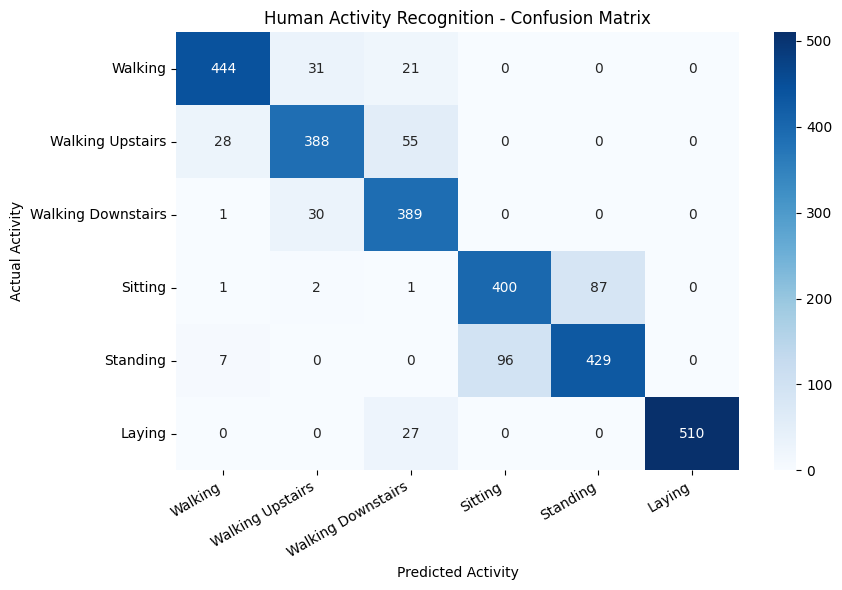

In [19]:
# Evaluate on separate test data
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

# Predict activities
probabilities = model.predict(X_test, verbose=0)
predictions = np.argmax(probabilities, axis=1)

# Activity names
labels = [
    'Walking',
    'Walking Upstairs',
    'Walking Downstairs',
    'Sitting',
    'Standing',
    'Laying'
]

print("\nClassification Report:\n")
print(classification_report(
    y_test, predictions,
    labels=[0, 1, 2, 3, 4, 5],
    target_names=labels,
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(y_test, predictions, labels=range(6))

plt.figure(figsize=(9, 6))
sns.heatmap(
    cm, annot=True, fmt='d',
    xticklabels=labels,
    yticklabels=labels,
    cmap='Blues'
)

plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")
plt.title("Human Activity Recognition - Confusion Matrix")
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [20]:
# Predict one sample from the test dataset
sample_number = 0

sample = X_test[sample_number:sample_number + 1]

prediction = model.predict(sample, verbose=0)
activity_id = np.argmax(prediction)

print("Predicted activity:", labels[activity_id])
print("Actual activity:", labels[y_test[sample_number]])
print("Confidence:", round(
    float(np.max(prediction)) * 100, 2
), "%")

# Save the trained model
model.save('/content/har_model.keras')

# Download the model to your computer
files.download('/content/har_model.keras')

Predicted activity: Standing
Actual activity: Standing
Confidence: 95.05 %


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>